# Entregable 3 · Modelos clásicos de regresión

Se preservan los notebooks de entregas anteriores. Ejecutar primero `venv\Scripts\python.exe modelos_clasicos.py` desde Precalculo. Este notebook inspecciona los artefactos de esa ejecución; no reentrena al abrirlo.

KNN, Ridge, Lasso, Random Forest y XGBoost comparten carga/reglas/particiones de entregable3.py. Los cinco folds externos son idénticos a los del SVM. Cada modelo usa cinco folds internos por estudiante para ajustar su grid. Test 202530 queda reservado. La comparación de familias por CV externa es exploratoria; no equivale a seleccionar también la familia dentro de cada búsqueda interna.

In [1]:
import json
import pandas as pd
from modelos_clasicos import OUTPUT, provenance
report = json.loads((OUTPUT / 'comparacion.json').read_text(encoding='utf-8'))
assert report['source_sha256'] == provenance(), 'Reejecutar modelos_clasicos.py'
display(pd.DataFrame([report['partition']]).T)
display(pd.DataFrame(report['test']))

,0
source_rows,1527
source_students,1506
missing_target,30
test_period,202530
train_periods,"[202310, 202330, 202410, 202430, 202510]"
purged_overlap_rows,0
purged_overlap_students,0
train_raw,1309
test_raw,188
excluded_train,0


,Modelo,RMSE,MAE,MAPE (%),R²
0,SVM lineal,0.927706,0.755443,29.664556,0.428543
1,Dummy media,1.256059,1.104467,42.314507,-0.047571
2,KNN,0.923270,0.754027,29.584495,0.433995
3,Ridge,0.917090,0.754511,29.572140,0.441545
4,Lasso,0.919650,0.753040,29.551967,0.438424
5,Random Forest,0.939635,0.765847,29.732021,0.413751
6,XGBoost,0.906274,0.728918,28.404775,0.454641


## Pipelines y parámetros

KNN, Ridge y Lasso reutilizan la preparación del SVM. Random Forest usa mediana, moda y codificación ordinal sin escalado; esos códigos introducen un orden artificial en las categorías nominales. XGBoost usa categorías nativas aprendidas dentro de fit, sin one-hot externo; las categorías nuevas se tratan como faltantes. Ningún vocabulario ni imputador se ajusta con validación/test. ID, periodo, nota_final y fila_fuente quedan fuera del modelo.

In [2]:
for key, model in report['models'].items():
    print(model['name'], model['preparation'])
    display(pd.DataFrame([{'Parámetro': p, 'Grid': str(v), 'Elegido': str(model['best_params'][p])} for p,v in model['grid'].items()]))
    display(pd.read_csv(OUTPUT / f'grid_{key}.csv'))
    display(pd.DataFrame(model['fold_audit']))

KNN Mediana, log1p en tiempos, StandardScaler; moda y one-hot con referencia. Distancias sobre variables transformadas.


,Parámetro,Grid,Elegido
0,modelo__n_neighbors,"[5, 11, 21, 31, 41, 61, 81, 101]",31
1,modelo__weights,"['uniform', 'distance']",distance
2,modelo__p,"[1, 2]",2


,param_modelo__n_neighbors,param_modelo__p,param_modelo__weights,mean_test_score,std_test_score,rank_test_score,RMSE
0,5,1,uniform,-0.886100,0.027206,31,0.886100
1,5,1,distance,-0.892505,0.030945,32,0.892505
2,5,2,uniform,-0.880357,0.034638,28,0.880357
3,5,2,distance,-0.884499,0.036749,29,0.884499
4,11,1,uniform,-0.854945,0.039717,9,0.854945
5,11,1,distance,-0.855463,0.040416,11,0.855463
6,11,2,uniform,-0.856825,0.039296,13,0.856825
7,11,2,distance,-0.857539,0.039890,14,0.857539
8,21,1,uniform,-0.857555,0.034477,15,0.857555
9,21,1,distance,-0.852358,0.036525,5,0.852358


,fold,fit_rows,validation_rows,fit_students,validation_students,shared_students,inner_folds,best_params
0,1,1047,262,1035,258,0,5,"{'modelo__n_neighbors': 31, 'modelo__p': 2, 'm..."
1,2,1047,262,1034,259,0,5,"{'modelo__n_neighbors': 21, 'modelo__p': 1, 'm..."
2,3,1047,262,1034,259,0,5,"{'modelo__n_neighbors': 11, 'modelo__p': 2, 'm..."
3,4,1047,262,1034,259,0,5,"{'modelo__n_neighbors': 21, 'modelo__p': 1, 'm..."
4,5,1048,261,1035,258,0,5,"{'modelo__n_neighbors': 21, 'modelo__p': 1, 'm..."


Ridge Mismo preprocesamiento del SVM: mediana, log1p en tiempos, escalado; moda y one-hot. Penalización L2.


...

,fold,fit_rows,validation_rows,fit_students,validation_students,shared_students,inner_folds,best_params
0,1,1047,262,1035,258,0,5,"{'modelo__max_depth': 6, 'modelo__min_samples_..."
1,2,1047,262,1034,259,0,5,"{'modelo__max_depth': None, 'modelo__min_sampl..."
2,3,1047,262,1034,259,0,5,"{'modelo__max_depth': None, 'modelo__min_sampl..."
3,4,1047,262,1034,259,0,5,"{'modelo__max_depth': None, 'modelo__min_sampl..."
4,5,1048,261,1035,258,0,5,"{'modelo__max_depth': None, 'modelo__min_sampl..."


XGBoost Mediana numérica y moda categórica; categorías nativas aprendidas en cada fit. Sin one-hot externo ni escalado; categorías nuevas pasan a faltantes. tree_method=hist, enable_categorical=True.


,Parámetro,Grid,Elegido
0,modelo__n_estimators,"[150, 300, 500]",300
1,modelo__max_depth,"[1, 2, 4]",2
2,modelo__learning_rate,"[0.01, 0.03, 0.1]",0.03


,param_modelo__learning_rate,param_modelo__max_depth,param_modelo__n_estimators,mean_test_score,std_test_score,rank_test_score,RMSE
0,0.01,1,150,-0.948485,0.015399,27,0.948485
1,0.01,1,300,-0.888062,0.015950,26,0.888062
2,0.01,1,500,-0.848658,0.019846,20,0.848658
3,0.01,2,150,-0.884242,0.019046,25,0.884242
4,0.01,2,300,-0.830608,0.025440,16,0.830608
5,0.01,2,500,-0.812481,0.034273,4,0.812481
6,0.01,4,150,-0.849984,0.024152,21,0.849984
7,0.01,4,300,-0.818862,0.032888,9,0.818862
8,0.01,4,500,-0.815182,0.037740,5,0.815182
9,0.03,1,150,-0.855591,0.018649,22,0.855591


,fold,fit_rows,validation_rows,fit_students,validation_students,shared_students,inner_folds,best_params
0,1,1047,262,1035,258,0,5,"{'modelo__learning_rate': 0.01, 'modelo__max_d..."
1,2,1047,262,1034,259,0,5,"{'modelo__learning_rate': 0.03, 'modelo__max_d..."
2,3,1047,262,1034,259,0,5,"{'modelo__learning_rate': 0.03, 'modelo__max_d..."
3,4,1047,262,1034,259,0,5,"{'modelo__learning_rate': 0.03, 'modelo__max_d..."
4,5,1048,261,1035,258,0,5,"{'modelo__learning_rate': 0.03, 'modelo__max_d..."


## Validación externa y comparación con el SVM

RMSE                 MAE             MAPE (%)            \
                   mean       std      mean       std       mean       std   
Modelo                                                                       
Dummy media    1.118000  0.029864  0.962418  0.028612  37.298790  2.028798   
KNN            0.855902  0.038794  0.683421  0.028642  25.849468  2.174586   
Lasso          0.828437  0.056014  0.654184  0.044510  24.436313  2.341388   
Random Forest  0.829569  0.029161  0.661607  0.028529  24.923079  1.938533   
Ridge          0.824343  0.052696  0.650605  0.040588  24.385327  2.220561   
SVM lineal     0.826140  0.046206  0.649312  0.039457  24.083710  2.036227   
XGBoost        0.814264  0.034055  0.645995  0.026611  24.184474  2.155902   

                     R²            
                   mean       std  
Modelo                             
Dummy media   -0.003463  0.004992  
KNN            0.410977  0.046260  
Lasso          0.447014  0.072305  
Random Forest  0.445783  0.052274  
Ridge          0.452596  0.068279  
SVM lineal     0.450132  0.064860  
XGBoost        0.466486  0.046238

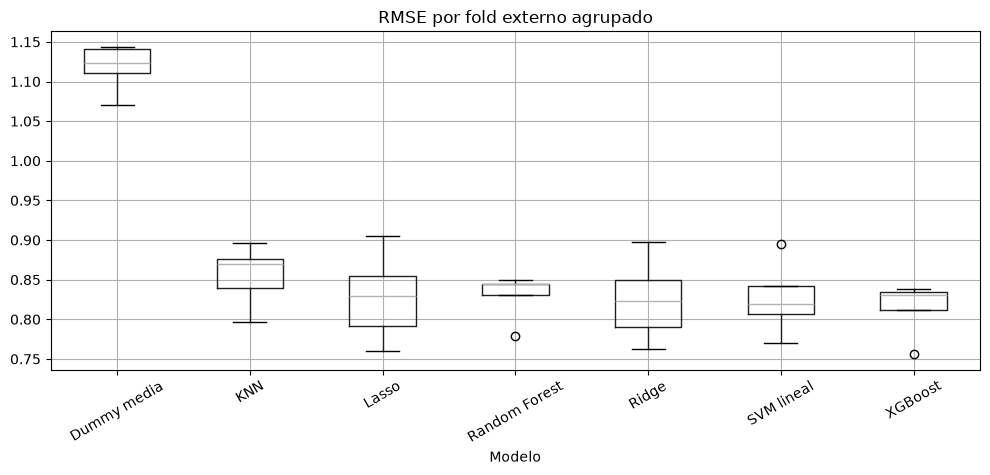

In [3]:
folds = pd.read_csv(OUTPUT / 'fold_metrics.csv')
display(folds.groupby('Modelo')[['RMSE','MAE','MAPE (%)','R²']].agg(['mean','std']))
import matplotlib.pyplot as plt
folds.boxplot(column='RMSE', by='Modelo', rot=30, figsize=(10,5))
plt.title('RMSE por fold externo agrupado')
plt.suptitle('')
plt.tight_layout()
plt.show()

## Incertidumbre y límites

Bootstrap de estudiantes del test, 1.000 remuestreos emparejados con el SVM. Δ RMSE negativo favorece al modelo. Comparaciones exploratorias sin corrección de multiplicidad; no elegir parámetros usando estos intervalos de test. No se recortan predicciones. Todas las métricas ponderan filas, no automáticamente estudiantes.

In [4]:
display(pd.DataFrame(report['paired_differences']))
display(pd.DataFrame(report['bootstrap']))
print('Menor RMSE externo entre clásicos:', report['selected_by_external_cv'])
print('Versiones:', report['versions'])

,Modelo,Δ RMSE vs SVM,IC 2.5%,IC 97.5%
0,KNN,-0.004436,-0.043382,0.037593
1,Ridge,-0.010615,-0.034201,0.005451
2,Lasso,-0.008056,-0.019821,0.002105
3,Random Forest,0.011930,-0.024352,0.050864
4,XGBoost,-0.021432,-0.052501,0.012527


,Modelo,Métrica,Estimación,IC 2.5%,IC 97.5%
0,SVM lineal,RMSE,0.927706,0.838232,1.018473
1,SVM lineal,MAE,0.755443,0.677509,0.838046
2,SVM lineal,R²,0.428543,0.320514,0.509091
3,Dummy media,RMSE,1.256059,1.174016,1.344446
4,Dummy media,MAE,1.104467,1.020392,1.194307
5,Dummy media,R²,-0.047571,-0.151286,-0.004056
6,KNN,RMSE,0.923270,0.837627,1.007819
7,KNN,MAE,0.754027,0.677824,0.834654
8,KNN,R²,0.433995,0.337399,0.510121
9,Ridge,RMSE,0.917090,0.833990,1.007181


Menor RMSE externo entre clásicos: XGBoost
Versiones: {'sklearn': '1.9.1', 'xgboost': '3.4.1'}
